# NetSense-QoR — M6 experiments on Kaggle

Runs every experiment config (baseline + 8 variants) with 3 seeds = 27 training runs, roughly 1–1.5 hours on a GPU.

**Setup** (same as the baseline notebook): *Add Input* → your `openabc-mini` dataset; *Settings*: **Accelerator = GPU**, **Internet = on**.

**Run it as a saved version** so it keeps running when you close the tab and the outputs are kept:
*Save Version* → *Save & Run All (Commit)*. When it has finished, open the version and download the notebook
(*File* → *Download notebook*, or the ⋮ menu); the results table, all per-run numbers and the bar chart are stored inside it.

In [1]:
!git clone https://github.com/tejaswini-18/netsense.git
%cd netsense
!git log --oneline -1

Cloning into 'netsense'...
remote: Enumerating objects: 133, done.
remote: Counting objects: 100% (133/133), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 133 (delta 61), reused 109 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (133/133), 285.29 KiB | 3.40 MiB/s, done.
Resolving deltas: 100% (61/61), done.
/kaggle/working/netsense
fec437c (HEAD -> main, origin/main, origin/HEAD) M6: experiment configs, model variants, ranking loss, multi-seed runner, Kaggle notebook


In [2]:
# Kaggle already has PyTorch (with GPU support), pandas, scipy, matplotlib, tqdm and pyyaml.
# Install only what is missing. Do NOT reinstall torch: that breaks the running session.
!pip install -q torch_geometric pytest
import torch, torch_geometric
print("torch", torch.__version__, "| PyG", torch_geometric.__version__, "| GPU:", torch.cuda.is_available())

torch 2.11.0+cu130 | PyG 2.8.1 | GPU: True


In [3]:
# Find the attached dataset (the folder that contains synthesisStatistics.pickle)
from pathlib import Path
DATA_ROOT = next(Path("/kaggle/input").rglob("synthesisStatistics.pickle")).parent
print("Dataset:", DATA_ROOT, "| design graphs:", len(list((DATA_ROOT / "graphs").glob("*.pt"))), "(expected 42)")

Dataset: /kaggle/input/datasets/tejaswinidharne18/openabc-mini | design graphs: 42 (expected 42)


In [4]:
# Quick check that everything works here before the long run
!NETSENSE_DATA_ROOT={DATA_ROOT} python -m pytest -q 2>&1 | tail -3


-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
45 passed, 432 warnings in 23.92s


In [5]:
# All experiments x 3 seeds. Progress bars are filtered out to keep the saved notebook small;
# each epoch line and each run's summary are still printed.
!python -m src.run_experiments --data-root {DATA_ROOT} --runs-dir /kaggle/working/runs --out /kaggle/working/results/experiments 2>&1 | tr '\r' '\n' | grep -vE 'it/s\]|s/it\]|^ *$'

##### baseline  seed 0 #####
Run folder: /kaggle/working/runs/baseline_20261117_143527  |  device: cuda
Samples: {'train': 4200, 'val': 900, 'test': 900}
Model parameters: 35,938
epoch   1 train 0.6124 | val loss 0.2835 | MAPE_and 9.80%  tau_and 0.169 | MAPE_delay 28.51%  tau_delay 0.069 | 6s  *best*
epoch   2 train 0.1606 | val loss 0.0911 | MAPE_and 8.89%  tau_and 0.149 | MAPE_delay 10.00%  tau_delay 0.079 | 5s  *best*
epoch   3 train 0.0746 | val loss 0.0654 | MAPE_and 5.17%  tau_and 0.155 | MAPE_delay 9.42%  tau_delay 0.088 | 5s  *best*
epoch   4 train 0.0597 | val loss 0.0585 | MAPE_and 2.03%  tau_and 0.065 | MAPE_delay 9.38%  tau_delay 0.082 | 5s  *best*
epoch   5 train 0.0569 | val loss 0.0582 | MAPE_and 4.82%  tau_and 0.081 | MAPE_delay 8.77%  tau_delay 0.080 | 5s  *best*
epoch   6 train 0.0569 | val loss 0.0617 | MAPE_and 3.51%  tau_and 0.042 | MAPE_delay 12.33%  tau_delay 0.077 | 5s
epoch   7 train 0.0573 | val loss 0.0582 | MAPE_and 4.80%  tau_and 0.057 | MAPE_delay 8.99%  t

| Experiment | tau_and | tau_delay | mape_and | mape_delay | top10_and | top10_delay | seeds |
|---|---|---|---|---|---|---|---|
| baseline | 0.107 ± 0.114 | 0.087 ± 0.023 | 2.074 ± 0.174 | 8.484 ± 0.195 | 0.025 ± 0.020 | 0.067 ± 0.031 | 3 |
| exp1_ratio | 0.461 ± 0.018 | 0.137 ± 0.034 | 0.718 ± 0.041 | 7.937 ± 0.216 | 0.167 ± 0.031 | 0.167 ± 0.042 | 3 |
| exp2_gin | 0.210 ± 0.018 | 0.093 ± 0.022 | 2.605 ± 0.787 | 8.192 ± 0.211 | 0.083 ± 0.012 | 0.117 ± 0.042 | 3 |
| exp2_sage | 0.093 ± 0.074 | 0.056 ± 0.038 | 3.111 ± 0.638 | 7.988 ± 0.245 | 0.100 ± 0.000 | 0.083 ± 0.031 | 3 |
| exp3_transformer | 0.257 ± 0.052 | 0.133 ± 0.021 | 2.396 ± 0.323 | 8.036 ± 0.374 | 0.075 ± 0.041 | 0.092 ± 0.047 | 3 |
| exp4_rankloss | 0.338 ± 0.025 | 0.135 ± 0.016 | 5.470 ± 0.216 | 9.128 ± 0.424 | 0.117 ± 0.047 | 0.158 ± 0.012 | 3 |
| exp5_graph_only | 0.003 ± 0.042 | -0.001 ± 0.006 | 2.067 ± 0.259 | 7.586 ± 0.103 | 0.042 ± 0.024 | 0.025 ± 0.000 | 3 |
| exp5_recipe_only | -0.006 ± 0.018 | 0.103 ± 0.004 | 66

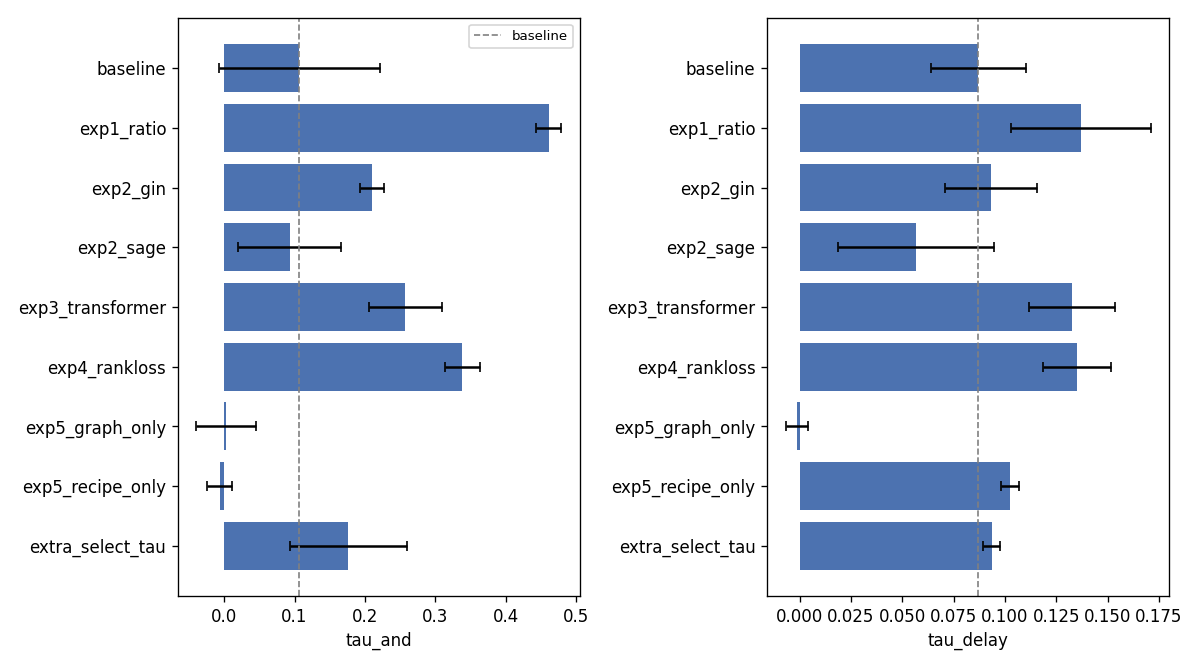

In [6]:
# Show the results (also stored inside this notebook when it is downloaded)
from IPython.display import Image, display
out = Path("/kaggle/working/results/experiments")
print((out / "results_table.md").read_text())
print("===== results_table.csv =====")
print((out / "results_table.csv").read_text())
display(Image(str(out / "experiments_bar.png")))